<a href="https://colab.research.google.com/github/Don4141/ProductPriceAI/blob/main/notebooks/Modal_app.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This notebook implements a Retrieval-Augmented Generation (RAG) pipeline for product price prediction using a training dataset of 800,000 Amazon products. Product summaries are transformed into 384-dimensional semantic embeddings using a Sentence Transformer and stored in ChromaDB alongside their categories and prices. For an unseen product, the pipeline retrieves five semantically similar products and provides their descriptions and prices as contextual information to GPT-5.1 to generate a price estimate. The RAG-based pricing model is subsequently evaluated using held-out test data.

#### Deploy multiple models to production including proprietary LLMs on Modal, RAG workflow with Frontier models, and Neural Network Models.

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [99]:
import os
os.chdir("/content")
#Clone repo after a new Colab runtime as the previous will be erased
!git clone https://github.com/Don4141/ProductPriceAI.git

# Directory containing the saved plots
PLOTS_DIR = Path("/content/ProductPriceAI/data/plots")

#Set repository as working directory
os.chdir("/content/ProductPriceAI")

#Verify
print("Repo exist", os.path.exists("/content/ProductPriceAI"))
print("Current working directory", os.getcwd())

fatal: destination path 'ProductPriceAI' already exists and is not an empty directory.
Repo exist True
Current working directory /content/ProductPriceAI


In [3]:
!pip install -q --upgrade bitsandbytes==0.48.2 trl==0.25.1 transformers==4.57.6

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [4]:
!pip uninstall -y gradio gradio-client diffusers

Found existing installation: gradio 6.31.0
Uninstalling gradio-6.31.0:
  Successfully uninstalled gradio-6.31.0
Found existing installation: gradio_client 2.7.2
Uninstalling gradio_client-2.7.2:
  Successfully uninstalled gradio_client-2.7.2
Found existing installation: diffusers 0.42.1
Uninstalling diffusers-0.42.1:
  Successfully uninstalled diffusers-0.42.1


In [5]:
#Install the list of required Python packages
%pip install -q -r requirements.txt

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tweepy 4.17.0 requires oauthlib<4,>=3.2.0, but you have oauthlib 4.0.1 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.


In [6]:
#Manage imports
import re
import math
import numpy as np
import torch
import wandb
import modal
import transformers
import trl
import peft
import bitsandbytes
import huggingface_hub
from tqdm import tqdm
import locale
import logging
from pricer.items import Item
from pricer.evaluator import evaluate, Tester
from tqdm.notebook import tqdm
from IPython.display import display, Image
from pathlib import Path
from transformers import AutoTokenizer
from google.colab import userdata
from huggingface_hub import login
import transformers
from peft import LoraConfig, PeftModel
from transformers import AutoModelForCausalLM, AutoTokenizer, TrainingArguments, set_seed, BitsAndBytesConfig
from trl import SFTTrainer, SFTConfig
from datasets import load_dataset, Dataset, DatasetDict
from datetime import datetime
import matplotlib.pyplot as plt
from agents.preprocessor import Preprocessor
from agents.specialist_agent import SpecialistAgent
from sentence_transformers import SentenceTransformer
import chromadb
from sklearn.manifold import TSNE
import plotly.graph_objects as go
from litellm import completion
from agents.items import Item
from agents.frontier_agent import FrontierAgent
from agents.neural_network_agent import NeuralNetworkAgent
from agents.ensemble_agent import EnsembleAgent

print("All LLM training libraries imported successfully!")

All LLM training libraries imported successfully!


In [7]:
#Load API credentials
for key in ["OPENAI_API_KEY", "ANTHROPIC_API_KEY", "GROQ_API_KEY", "GITHUB_TOKEN",
            "HF_TOKEN", "MODAL_TOKEN_ID", "MODAL_TOKEN_SECRET"]:
  os.environ[key] = userdata.get(key)

In [8]:
#Verify if API keys are loaded
for key in ["OPENAI_API_KEY", "ANTHROPIC_API_KEY", "GROQ_API_KEY", "GITHUB_TOKEN",
            "HF_TOKEN", "MODAL_TOKEN_ID", "MODAL_TOKEN_SECRET"]:
    print(f"{key}: {'loaded' if os.getenv(key) else 'Missing'}")

OPENAI_API_KEY: loaded
ANTHROPIC_API_KEY: loaded
GROQ_API_KEY: loaded
GITHUB_TOKEN: loaded
HF_TOKEN: loaded
MODAL_TOKEN_ID: loaded
MODAL_TOKEN_SECRET: loaded


In [73]:
#Verify authentication with Modal
!modal secret list

                                    Secrets                                     
┏━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃ Name               ┃ Created at           ┃ Created by ┃ Last used at        ┃
┡━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ huggingface-secret │ 2026-11-19 10:39 UTC │ don4141    │ 2026-11-24 05:19    │
│                    │                      │            │ UTC                 │
└────────────────────┴──────────────────────┴────────────┴─────────────────────┘


In [10]:
#Initialize the preprocessor and transform a sample product description into a concise,
#structured summary using `groq/openai/gpt-oss-20b` as the default LLM.

preprocessor = Preprocessor()
text = preprocessor.preprocess("Quadcast HyperX condenser mic, connects via usb-c to your computer for crystal clear audio")
print(text)

Title: HyperX Quadcast USB-C Condenser Mic  
Category: Electronics  
Brand: HyperX  
Description: A premium condenser microphone that plugs directly into your computer via USB‑C for crystal‑clear audio.  
Details: Features four omnidirectional, cardioid, and sub‑cardioid pickup patterns, onboard mute button, and built‑in headphone monitoring for instant, high‑quality sound.


In [90]:
# Deploy the fine-tuned Llama-3.2-3B model to Modal
!modal deploy /content/ProductPriceAI/other/llama_3_2_3b_pricer_service.py

⠸ Creating objects...
⠦ Creating objects...
└── ⠸ Creating mount 
    /content/ProductPriceAI/other/llama_3_2_3b_pricer_service.py: Uploaded 0/1 
⠏ Creating objects...
└── ⠦ Creating mount 
    /content/ProductPriceAI/other/llama_3_2_3b_pricer_service.py: Uploaded 0/1 
⠹ Creating objects...
├── ✓ Uploaded /content/ProductPriceAI/other/llama_3_2_3b_pricer_service.py
⠴ Creating objects...
├── ✓ Uploaded /content/ProductPriceAI/other/llama_3_2_3b_pricer_service.py
⠦ Creating objects...
├── ✓ Uploaded /content/ProductPriceAI/other/llama_3_2_3b_pricer_service.py
└── ✓ Created Function Pricer.*.
✓ Created objects.
├── ✓ Uploaded /content/ProductPriceAI/other/llama_3_2_3b_pricer_service.py
└── ✓ Created Function Pricer.*.
✓ App deployed in 1.946s! 🎉

View Deployment: 
]8;id=254095;https://modal.com/apps/don4141/main/deployed/productpriceai-llama-3-2-3b\https://modal.com/apps/don4141/main/deployed/productpriceai-llama-3-2-3b]8;;\


In [91]:
!modal app list

                                      Apps                                      
                                                                                
                              Descript                      Created    Stopped  
  App ID                      ion        State      Tasks   at         at       
 ────────────────────────────────────────────────────────────────────────────── 
  ap-tJsfNZa9jBrfnmdR9V4q3N   productp   deployed   0       2026-11-            
                              riceai-l                      27 21:58            
                              lama-3-2                      UTC                 
                              -3b                                               
  ap-ZOdHrpPfcLxUshzMpwHHia   pricer-s   deployed   0       2026-11-            
                              ervice                        21 12:08            
                                                            UTC                 
                            

##### Load the preprocessed products dataset from Hugging Face. This has the 819,998 preprocessed product descriptions.

In [11]:
#Load the preprocessed product dataset from Hugging Face
username = "sadjei65320"
dataset = f"{username}/items_full"

#Retrieve the training, validation, and test datasets
train, val, test = Item.from_hub(dataset)

print(f"Loaded {len(train):,} training items, {len(val):,} validation items, {len(test):,} test items")

README.md:   0%|          | 0.00/744 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/237M [00:00<?, ?B/s]

data/validation-00000-of-00001.parquet:   0%|          | 0.00/3.00M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/3.00M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/799998 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Loaded 799,998 training items, 10,000 validation items, 10,000 test items


Initialize a persistent ChromaDB vector database and load a pretrained Sentence Transformer model to generate semantic embeddings from product descriptions.

In [12]:
#Define the path for the persistent ChromaDB vector store
DB = "products_vectorstore"

#Initialize the persistent ChromaDB client
client = chromadb.PersistentClient(path=DB)

#Load pretrained sentence embedding model
encoder = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Desmonstrate that the text embedding generation works. Convert a sample text into a 384-dimensional numerical embedding and inspect its shape and values.

In [18]:
#Generate a semantic embedding from a sample text. Pass in a list of texts, get back a numpy array of vectors
vector = encoder.encode(["A proficient AI engineer who has almost reached the finale of AI Engineering Core Track!"])[0]
print(vector.shape)
print(vector[:20])

(384,)
[-0.05682341 -0.06704656  0.04411297  0.00598605 -0.02289487 -0.02953007
  0.05563691  0.03426656 -0.10852939 -0.0381691  -0.07438725 -0.10366429
  0.01691481  0.00133926 -0.06861915  0.08993534 -0.01451864 -0.02438854
  0.00421855 -0.09629925]


Generate semantic embeddings for all 799,998 training product summaries in batches of 1,000 and store them in ChromaDB alongside their descriptions, categories, prices, and unique identifiers. Subset and visualize few of the product embeddings.

In [19]:
#Generate and store product embeddings
collection_name = "products"
collection = client.create_collection(collection_name)
for i in tqdm(range(0, len(train), 1000)):
    documents = [item.summary for item in train[i: i+1000]]
    #Convert product summaries into semantic embeddings
    vectors = encoder.encode(documents).astype(float).tolist()
    #Extract product categories and prices as metadata
    metadatas = [{"category": item.category, "price": item.price} for item in train[i: i+1000]]
    ids = [f"doc_{j}" for j in range(i, i+1000)]
    ids = ids[:len(documents)]
    #Store embeddings, summaries, and metadata in ChromaDB
    collection.add(ids=ids, documents=documents, embeddings=vectors, metadatas=metadatas)
collection = client.get_or_create_collection(collection_name)

  0%|          | 0/800 [00:00<?, ?it/s]

In [20]:
#Subset and visualize vectors/embeddings of 10,000 products from the collections stored in chroma DB
MAXIMUM_DATAPOINTS = 10_000

In [21]:
#Define product categories and assign colors to facilitate visual differentiation
CATEGORIES = ['Appliances', 'Automotive', 'Cell_Phones_and_Accessories', 'Electronics','Musical_Instruments', 'Office_Products', 'Tools_and_Home_Improvement', 'Toys_and_Games']
COLORS = ['cyan', 'blue', 'brown', 'orange', 'yellow', 'green' , 'purple', 'red']

In [22]:
#Retrieve product embeddings, summaries, and metadata
result = collection.get(include=['embeddings', 'documents', 'metadatas'], limit=MAXIMUM_DATAPOINTS)
vectors = np.array(result['embeddings'])
documents = result['documents']
categories = [metadata['category'] for metadata in result['metadatas']]
colors = [COLORS[CATEGORIES.index(c)] for c in categories]

In [23]:
#Apply t-distributed Stochastic Neighbor Embedding (t-SNE) to project the 384-dimensional product embeddings into two dimensions for visualization
tsne = TSNE(n_components=2, random_state=42)
#Reduce the dimensionality of product embeddings from 384 to 2
reduced_vectors = tsne.fit_transform(vectors)

In [27]:
#Generate 2D scatter plot of the reduced product embeddings, color-coded by category, to explore semantic clustering and relationships among products.
fig = go.Figure(data=[go.Scatter(
    x=reduced_vectors[:, 0],
    y=reduced_vectors[:, 1],
    mode='markers',
    marker=dict(size=4, color=colors, opacity=0.7),
    text=[f"Category: {c}<br>Text: {d[:50]}..." for c, d in zip(categories, documents)],
    hoverinfo='text'
)])

fig.update_layout(
    title='2D Chroma Vectorstore Visualization',
    xaxis_title="t-SNE Dimension 1",
    yaxis_title="t-SNE Dimension 2",
    width=850,
    height=700,
    margin=dict(r=20, b=10, l=10, t=40)
)

fig.show()

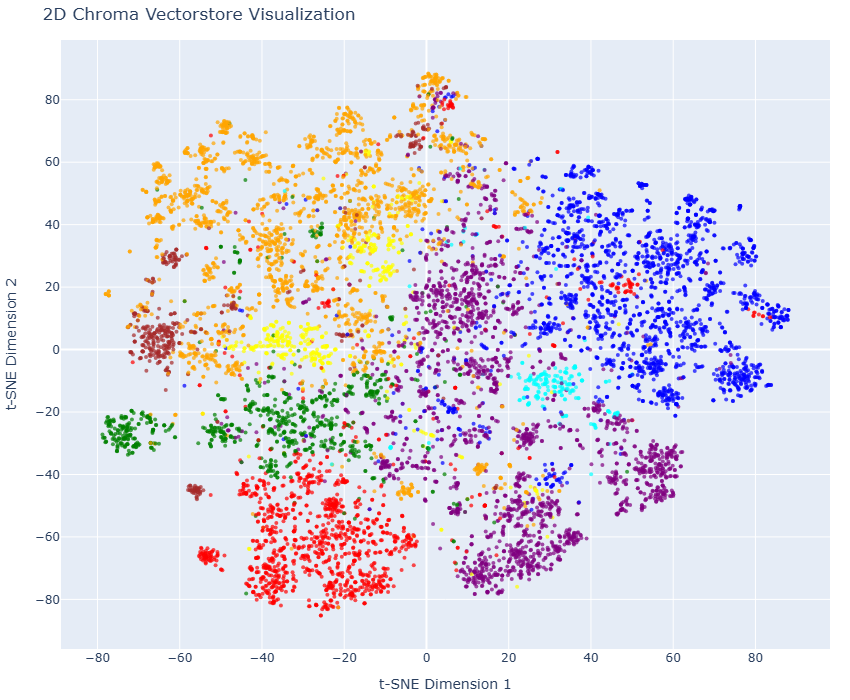

In [101]:
#Display saved plot for display in GitHub
display(Image(filename=str(PLOTS_DIR / "2D_tSNE_Vector_Embeddings.png"), width=800))

In [28]:
#Try with three-dimensional dimensionality reduction
tsne = TSNE(n_components=3, random_state=42)
reduced_vectors = tsne.fit_transform(vectors)

In [30]:
# Create the 3D scatter plot
fig = go.Figure(data=[go.Scatter3d(
    x=reduced_vectors[:, 0],
    y=reduced_vectors[:, 1],
    z=reduced_vectors[:, 2],
    mode='markers',
    marker=dict(size=2, color=colors, opacity=0.7),
    text=[f"Category: {c}<br>Text: {d[:50]}..." for c, d in zip(categories, documents)],
    hoverinfo='text'
)])

fig.update_layout(
    title='3D Chroma Vector Store Visualization',
    scene=dict(xaxis_title='x', yaxis_title='y', zaxis_title='z'),
    width=850,
    height=800,
    margin=dict(r=20, b=10, l=10, t=40)
)

fig.show()

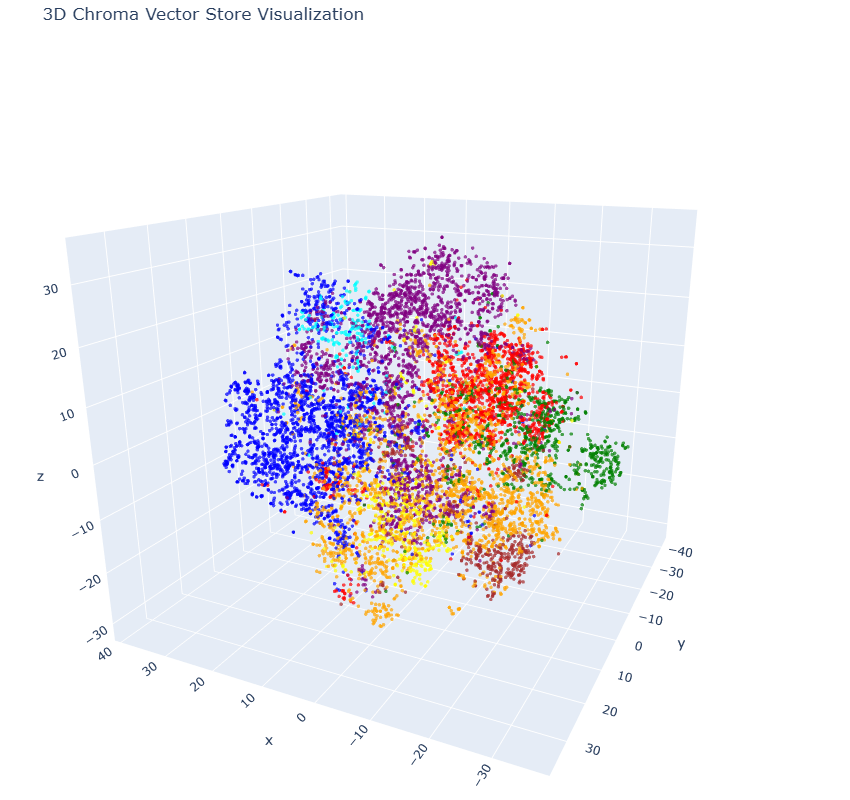

In [103]:
#Display saved plot for display in GitHub
display(Image(filename=str(PLOTS_DIR / "3D_tSNE_Vector_Embeddings.png"), width=800))

In [31]:
#Define a reusable function that takes an product discription and transform it
#into a semantic embedding using the pretrained Sentence Transformer
def vector(item):
    return encoder.encode(item.summary)

In [32]:
#Define another reusable function that when given a product discription, transforms it into a semantic
#embedding using the vector function defined above, then queries the ChromaDB using the product embedding
#and retrieves five nearest (most semantically similar) product summaries and their associated prices
def find_similars(item):
    vec = vector(item)
    #Search the vector database for the five nearest products
    results = collection.query(query_embeddings=vec.astype(float).tolist(), n_results=5)

    #Extract and retrieve product summaries and prices
    documents = results['documents'][0][:]
    prices = [m['price'] for m in results['metadatas'][0][:]]
    return documents, prices

In [44]:
test[1]

<Art Profolio The Original Presentation Books, 11 x 17 Inches (ANIA1212) = $19.65>

In [45]:
#Test the semantic similarity retrieval function above by applying it to the first item in the test set.
find_similars(test[2])

(['Title: Shoxtec Front Left Strut Assembly Replacement  \nCategory: Automotive  \nBrand: Shoxtec  \nDescription: A complete pre‑assembled front left strut kit for 2002‑2003 Lexus ES300/ES350 and Toyota Camry models.  \nDetails: Features ISO‑certified shock absorber, oil seal and rubber dust boot for durability, no special tools needed for installation, and a 12‑month warranty.',
  'Title: Shoxtec Full Set Struts Coil Spring Assembly  \nCategory: Automotive Parts  \nBrand: Shoxtec  \nDescription: Fully pre‑assembled strut and coil spring kit for 2007‑2011 Toyota Camry, 2007‑2009 Lexus ES350, and 2006‑2012 Toyota Avalon.  \nDetails: ISO‑certified, OEM‑spec compliant components with durable oil seals, dust boots, and a hollow bumper to protect against road debris; includes lifetime warranty.',
  'Title: Rear Pair Complete Strut Replacement Kit  \nCategory: Automotive Parts  \nBrand: Shoxtec  \nDescription: Full replacement rear strut kit for 2004‑2007 Toyota Highlander and 2004‑2007 Lexu

Retrieve the five most semantically similar training products and their associated prices for the sample product.

---

GPT-5.1 is employed here to serve as the generative component of the RAG pipeline responsible for estimating the price of an unseen product using its description and relevant pricing information retrieved from ChromaDB.

Specifically, it receives a given product's preprocessed summary, the descriptions and known prices of the five most semantically similar products retrieved from ChromaDB, and uses its contextual understanding to assess the given product against the retrieved products, considering their features, specifications, and prices. It then generates a price estimate without requring additional model fine-tuning.

Define a function that will format the retrieved five most semantically similar product descriptions and their known prices into contextual information that can guide the LLM in estimating the price of an unseen product.

In [46]:
#Construct contextual information from retrieved products and prices
def make_context(similars, prices):
    #Introduce the retrieved products as pricing references
    message = "For context, here are some other items that might be similar to the item you need to estimate.\n\n"
    # Append each retrieved product summary and its known price
    for similar, price in zip(similars, prices):
        message += f"Potentially related product:\n{similar}\nPrice is ${price:.2f}\n\n"
    return message

Apply the three functions above to a product from the test set, inspect the retrieved context (the formatted contextual information) for completeness before passing it to the LLM.

In [47]:
#Retrieve similar products and their associated prices
documents, prices = find_similars(test[0])
#Generate and display the retrieval-augmented context
print(make_context(documents, prices))

For context, here are some other items that might be similar to the item you need to estimate.

Potentially related product:
Title: 12" Batman Figure  
Category: Toys & Games – Collectibles  
Brand: Mattel  
Description: A 12‑inch articulated Batman action figure modeled after the Warner Bros. film.  
Details: Features 9 points of articulation, movie‑accurate body suit, and a soft‑goods cape.
Price is $32.99

Potentially related product:
Title: DC Comics Unlimited 6" Batman Collector Figure  
Category: Toys & Games  
Brand: Mattel  
Description: A highly detailed, 6‑inch collectible Batman figure from DC Comics Unlimited, crafted by Four Horsemen Studios.  
Details: Features classic comic‑book styling, superior articulation, and authentic sculpting for display and posing.
Price is $22.99

Potentially related product:
Title: 6" Batman Dark Knight Action Figure  
Category: Toys & Games  
Brand: Mattel  
Description: A 6-inch action figure of Batman from The Dark Knight, featuring detaile

Construct an LLM prompt containing a given product and the retrieved context. To do this, combine the given product's summary/description with the retrieved product descriptions and prices from the vectorStore to OpenAI-compatible message for GPT-5.1's price prediction.

In [48]:
#Turn the above functions into an open AI style messages
def messages_for(item, similars, prices):
    #Define an instruction for the LLM
    message = f"Estimate the price of this product. Respond with the price, no explanation\n\n{item.summary}\n\n"
    #Augment the prompt with the retrieved products and their known prices
    message += make_context(similars, prices)
    #Return the prompt in an OpenAI-compatible message format
    return [{"role": "user", "content": message}]

Generate and inspect the price estimation prompt to verify that the unseen product and retrieved contextual information are correctly incorporated.

In [49]:
documents, prices = find_similars(test[0])
print(messages_for(test[0], documents, prices)[0]['content'])

Estimate the price of this product. Respond with the price, no explanation

Title: Batman 6" Ultimate Figure Pack  
Category: Toys  
Brand: Mattel  
Description: A 6‑inch poseable Batman figure set that transforms Bruce Wayne’s office into a retro Batcave with classic accessories.  
Details: Includes a Bruce Wayne head, Batman figure, swiveling bookcase, hidden weapons, and iconic gadgets.

For context, here are some other items that might be similar to the item you need to estimate.

Potentially related product:
Title: 12" Batman Figure  
Category: Toys & Games – Collectibles  
Brand: Mattel  
Description: A 12‑inch articulated Batman action figure modeled after the Warner Bros. film.  
Details: Features 9 points of articulation, movie‑accurate body suit, and a soft‑goods cape.
Price is $32.99

Potentially related product:
Title: DC Comics Unlimited 6" Batman Collector Figure  
Category: Toys & Games  
Brand: Mattel  
Description: A highly detailed, 6‑inch collectible Batman figure fr

Implement the RAG-based price prediction. Let's define a function that calls GPT-5.1 in RAG mode. This function will take the description of a given item,retrieves its five most semantically similar products from ChromaDB (RAG) then call GPT-5.1 and pass in the product description and the retrieved related items as extra context to estimate the product's price.

In [67]:
#Define the function
def gpt_5__1_rag(item):
    documents, prices = find_similars(item)
    response = completion(model="gpt-5.1", messages=messages_for(item, documents, prices), reasoning_effort="none", seed=42)
    #Extract the predicted price from the LLM response
    return response.choices[0].message.content

In [69]:
#Retrieve the ground-truth price of the given test product for comparison with the RAG-generated price estimate.
actual_item_price = test[0].price
rag_generated_price = gpt_5__1_rag(test[0])

print(f"Actual Price: ${actual_item_price:.2f}")
print(f"RAG Generated Price: {rag_generated_price}")

Actual Price: $58.73
RAG Generated Price: $39.99


In [70]:
#Evaluate the predictive performance of the RAG-based GPT-5.1 pricing model on the test set
gpt_5__1_rag_tester = evaluate(gpt_5__1_rag, test, size=1000)

  0%|          | 0/1000 [00:00<?, ?it/s]

$19 $20 $3 $8 $55 $319 $1 $36 $17 $1 $10 $134 $27 $2 $75 $8 $16 $15 $23 $40 $25 $75 $19 $6 $105 $39 $9 $8 $24 $0 $10 $15 $2 $20 $70 $0 $11 $71 $150 $40 $10 $133 $16 $5 $90 $43 $20 $27 $15 $3 $7 $2 $70 $47 $71 $1 $0 $5 $2 $44 $120 $9 $10 $4 $12 $69 $13 $2 $60 $13 $9 $4 $10 $0 $20 $106 $5 $8 $10 $0 $2 $10 $9 $21 $40 $32 $6 $5 $50 $44 $2 $21 $2 $4 $10 $2 $340 $30 $20 $5 $2 $87 $75 $16 $10 $10 $5 $118 $14 $36 $90 $42 $6 $6 $10 $322 $5 $9 $76 $4 $20 $14 $16 $2 $5 $15 $16 $21 $2 $7 $25 $9 $32 $16 $17 $8 $5 $0 $3 $91 $85 $5 $12 $117 $8 $7 $16 $7 $0 $0 $2 $23 $1 $21 $112 $80 $90 $70 $22 $9 $30 $12 $42 $4 $34 $39 $4 $5 $25 $5 $5 $2 $10 $11 $1 $21 $15 $30 $100 $62 $20 $1 $163 $59 $2 $505 $25 $9 $34 $7 $42 $10 $0 $20 $1 $26 $41 $4 $5 $0 $10 $85 $0 $3 $15 $14 $10 $1 $4 $4 $10 $6 $300 $0 $20 $0 $4 $57 $49 $2 $21 $0 $324 $5 $69 $5 $11 $40 $10 $5 $16 $54 $31 $22 $2 $3 $34 $20 $81 $1 $52 $6 $60 $5 $13 $6 $13 $19 $45 $2 $66 $333 $11 $5 $0 $18 $44 $11 $75 $55 $67 $0 $6 $176 $5 $25 $20 $2 $7 $47 $50 $0 $

In [71]:
#Generate a performance plot
gpt_5__1_rag_tester.report()

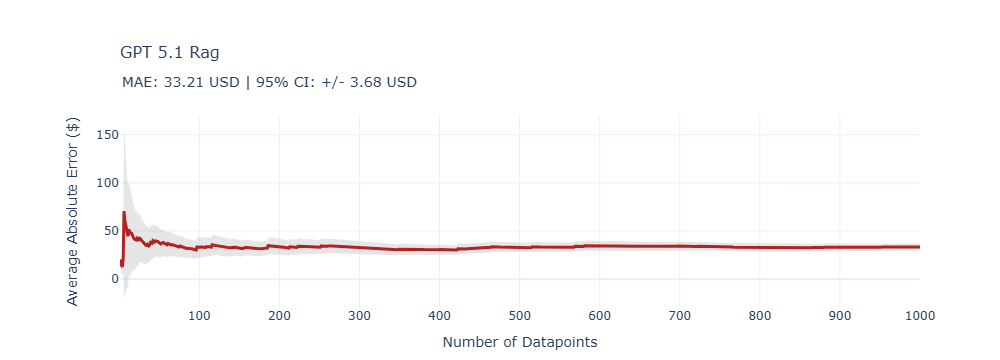

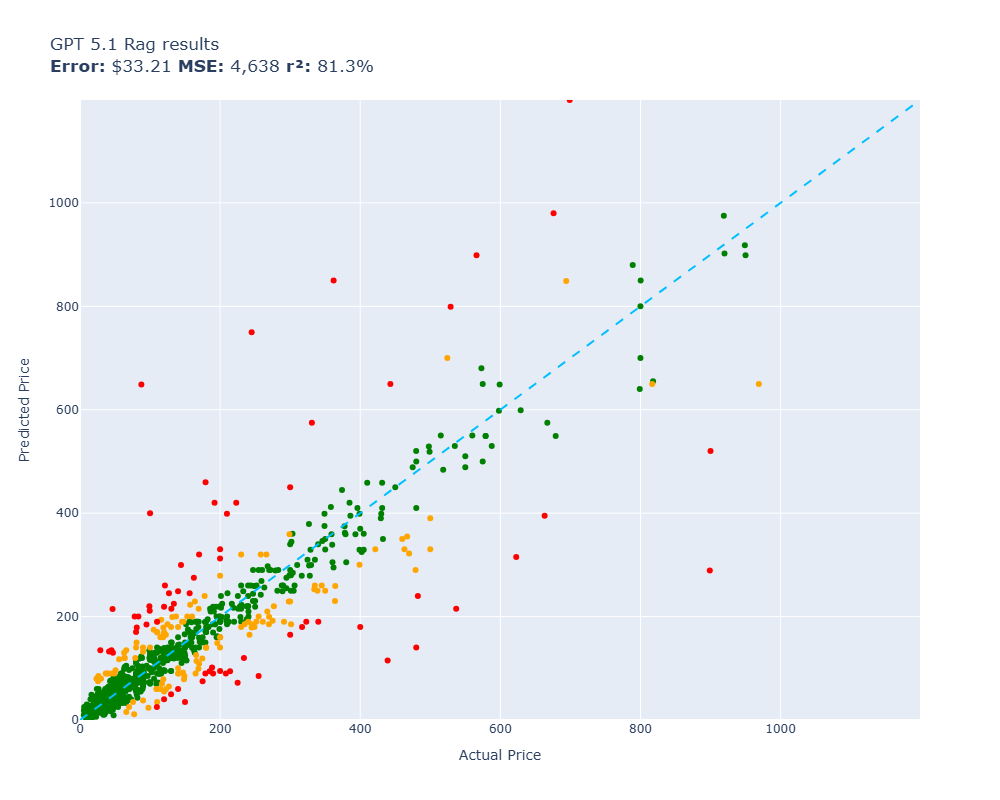

In [104]:
#Display saved plot for display in GitHub
display(Image(filename=str(PLOTS_DIR / "GPT_5_RAG_MAE.png"), width=850))
display(Image(filename=str(PLOTS_DIR / "GPT_5_RAG_MSE.png"), width=850))

In [92]:
Pricer = modal.Cls.from_name("productpriceai-llama-3-2-3b", "Pricer")
pricer = Pricer()

In [93]:
#Calls modal in the cloud and returns a summary of an item from our deployed model on modal
def specialist(item):
    return pricer.price.remote(item.summary)

In [94]:
#Function to strip out a number when the model returns a text
def get_price(reply):
    reply = reply.replace("$", "").replace(",", "")
    match = re.search(r"[-+]?\d*\.\d+|\d+", reply)
    return float(match.group()) if match else 0

Download the Neural Network model and weights stored on Hugging Face

In [81]:
#Integrate the downloaded artifacts into your inference runner
from agents.artificial_neural_network import ArtificialNeuralNetworkInference

# Initialize the ANN inference runner
runner = ArtificialNeuralNetworkInference()
# Reconstruct the neural network and initialize preprocessing
runner.setup()
# Load the trained model weights and associated vectorizer
runner.load("sadjei65320/ProductPriceAI-ArtificialNeuralNetwork")

# Predict product prices using the trained ANN
def artificial_neural_network(item):
    return runner.inference(item.summary)

In [82]:
#Evaluate the trained ANN downloaded from Hugging Face
ann_tester = evaluate(artificial_neural_network, test, size=1000)

  0%|          | 0/1000 [00:00<?, ?it/s]

$32 $69 $121 $10 $67 $451 $0 $17 $81 $57 $4 $274 $44 $8 $13 $31 $6 $60 $18 $73 $51 $295 $142 $33 $85 $206 $26 $145 $4 $33 $42 $1 $6 $38 $117 $85 $98 $151 $16 $67 $3 $141 $56 $65 $10 $90 $48 $28 $39 $5 $26 $6 $150 $86 $50 $17 $23 $34 $1 $97 $122 $39 $1 $7 $10 $29 $260 $12 $8 $3 $19 $92 $7 $3 $144 $67 $108 $10 $32 $53 $29 $123 $44 $55 $44 $22 $33 $77 $35 $63 $7 $35 $2 $3 $12 $12 $259 $22 $15 $27 $25 $1 $75 $37 $34 $14 $13 $103 $3 $4 $192 $37 $1 $60 $247 $404 $10 $74 $48 $66 $5 $317 $39 $20 $46 $7 $1 $143 $28 $13 $73 $24 $27 $4 $29 $40 $46 $10 $47 $89 $34 $69 $37 $26 $1 $5 $47 $45 $77 $13 $2 $39 $24 $41 $84 $29 $65 $12 $7 $10 $31 $16 $58 $12 $56 $23 $294 $27 $54 $68 $553 $7 $10 $8 $62 $15 $18 $18 $108 $83 $127 $5 $47 $110 $9 $20 $14 $138 $142 $15 $23 $6 $10 $1 $25 $44 $127 $19 $31 $4 $21 $182 $13 $26 $128 $9 $13 $46 $54 $30 $32 $17 $22 $42 $168 $7 $49 $17 $92 $25 $31 $6 $334 $20 $54 $18 $14 $58 $18 $17 $12 $52 $91 $63 $24 $11 $65 $82 $43 $17 $256 $105 $32 $42 $7 $38 $36 $47 $32 $51 $232 $

In [83]:
#Generate a performance plot for the downloaded trained ANN model
ann_tester.report()

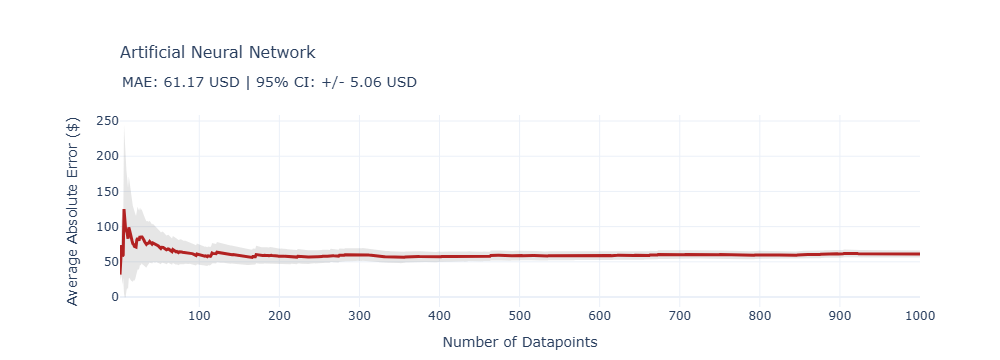

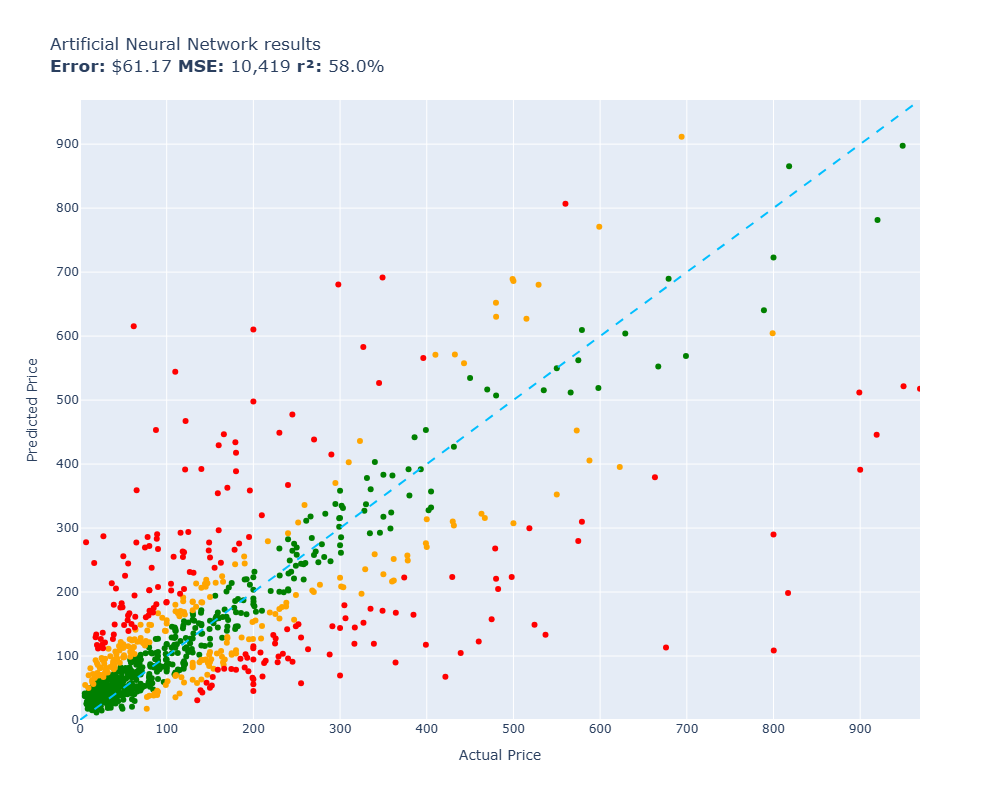

In [106]:
#Display saved plot for display in GitHub
display(Image(filename=str(PLOTS_DIR / "ANN_Test_Performance_MAE.png"), width=850))
display(Image(filename=str(PLOTS_DIR / "ANN_Test_Performance_MSE.png"), width=850))

In [95]:
#Create an emsemble function that will take the frontier RAG (GPT 5.1 and RAG), the specialist model and the ANN model
#This combines 80% of the output from the frontier RAG, 10% of the specialist model and 10% of the ANN and returns an average price
def ensemble(item):
    price1 = get_price(gpt_5__1_rag(item))
    price2 = specialist(item)
    price3 = artificial_neural_network(item)
    return price1 * 0.8 + price2 * 0.1 + price3 * 0.1

In [97]:
#Apply the above function on the entire test dataset
ensemble_tester = evaluate(ensemble, test, 1000)

  0%|          | 0/1000 [00:00<?, ?it/s]

$15 $20 $22 $2 $35 $367 $1 $37 $18 $7 $10 $149 $20 $0 $51 $11 $16 $6 $24 $37 $22 $117 $28 $1 $101 $73 $5 $7 $22 $6 $6 $14 $1 $26 $53 $15 $21 $58 $142 $47 $9 $130 $11 $13 $74 $41 $21 $17 $11 $3 $9 $2 $67 $151 $40 $1 $5 $0 $2 $50 $118 $10 $8 $2 $10 $50 $36 $0 $45 $17 $10 $10 $10 $1 $32 $111 $7 $5 $5 $5 $3 $23 $9 $8 $33 $29 $0 $9 $45 $43 $1 $22 $2 $3 $7 $6 $316 $31 $18 $9 $2 $78 $76 $6 $7 $17 $6 $104 $10 $30 $89 $39 $11 $4 $9 $303 $4 $19 $65 $10 $29 $49 $19 $4 $5 $14 $13 $27 $6 $8 $15 $11 $31 $13 $16 $10 $12 $2 $7 $102 $69 $0 $15 $88 $7 $7 $18 $13 $1 $1 $2 $26 $8 $21 $95 $78 $62 $72 $18 $7 $9 $12 $35 $2 $28 $29 $45 $1 $27 $11 $54 $3 $6 $14 $1 $14 $17 $26 $104 $60 $27 $0 $112 $58 $1 $403 $17 $13 $14 $10 $30 $9 $1 $10 $4 $29 $47 $5 $7 $0 $7 $54 $2 $5 $27 $10 $5 $6 $8 $5 $16 $5 $234 $11 $28 $1 $9 $49 $52 $1 $15 $1 $315 $7 $76 $6 $8 $35 $6 $3 $11 $47 $39 $29 $5 $1 $39 $34 $87 $4 $57 $25 $61 $2 $11 $6 $15 $29 $30 $4 $59 $234 $13 $6 $0 $17 $50 $19 $73 $65 $83 $6 $1 $101 $5 $26 $11 $4 $7 $43 $53

In [98]:
#Generate a performance plot for the downloaded trained ANN model
ensemble_tester.report()

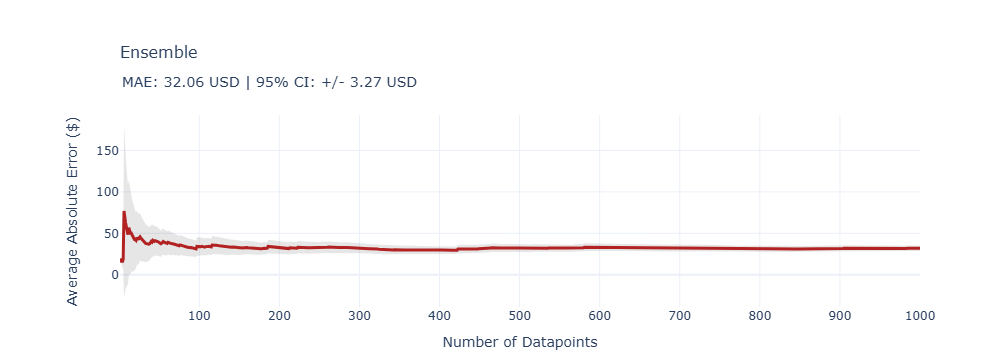

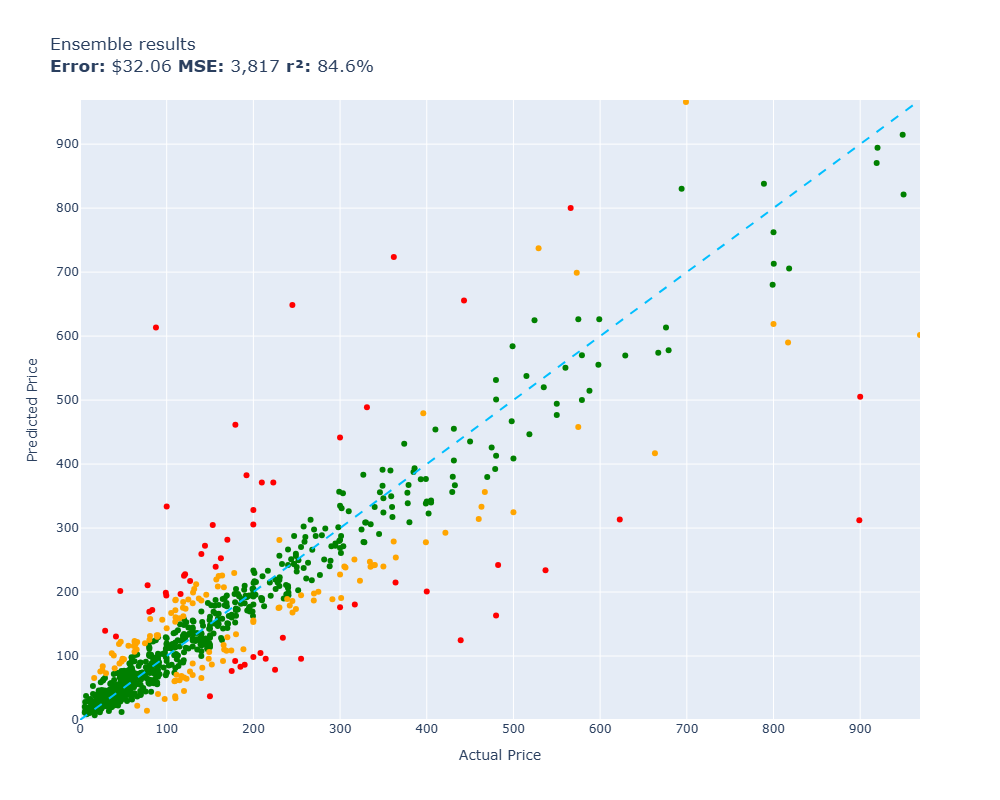

In [105]:
#Display saved plot for display in GitHub
display(Image(filename=str(PLOTS_DIR / "ensemble_MAE.png"), width=850))
display(Image(filename=str(PLOTS_DIR / "ensemble_MSE.png"), width=850))

Put the notebook into production ready python module

In [113]:
#Initialize the Frontier Agent and estimate a product's price using GPT-5.1 and RAG
agent = FrontierAgent(collection)
#Estimate the price of the Shure MV7+ microphone using the Frontier Agent
agent.price("Shure MV7+ professional podcaster microphone with usb-c and XLR outputs")

269.0

In [114]:
#Initialize the ANN agent and load the trained weights and vectorizer from Hugging Face
agent = NeuralNetworkAgent()
# Estimate the product's price using the trained Artificial Neural Network
agent.price("Shure MV7+ professional podcaster microphone with usb-c and XLR outputs")

1634.816650390625

In [115]:
#Initialize the Ensemble Agent with its constituent predictive agents
agent = EnsembleAgent(collection)
#Generate an ensemble-based price estimate by combining individual model predictions
agent.price("Shure MV7+ professional podcaster microphone with usb-c and XLR outputs")

293.6175445556641

#### Summary

The Frontier, Neural Network, and Ensemble agents are initialized and tested on product descriptions to demonstrate their price prediction capabilities. For the Shure MV7+ microphone, the Ensemble Agent generates the most plausible price estimate, followed closely by the Frontier Agent, while the ANN substantially overestimates the price. These preliminary results illustrate the potential benefit of combining complementary predictive models, although systematic evaluation on the held-out test dataset is required to establish their relative performance.